# Phân tích đa chuỗi thời gian theo vùng

Mỗi chuỗi là số đơn tiếp nhận theo ngày của một mã vùng trong LaDe-D Jilin. Phân tích dùng toàn kỳ và cửa sổ 27/06–02/10 để kiểm tra độ nhạy.

## Dữ liệu đầu vào và phạm vi quan sát

Mỗi dòng là một đơn. Quy trình kiểm tra khóa `order_id`, đối chiếu `ds` với ngày tiếp nhận và kiểm tra mã vùng trước khi lập bảng vùng–ngày. Tổng đơn sau tổng hợp phải bằng số đơn đầu vào, kể cả đơn giao quá 24 giờ. Năm 2022 là quy ước kỹ thuật để biểu diễn ngày.

In [1]:
from pathlib import Path
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from src.config import DEMAND_DATE_COLUMN as DATE
from src.data_loader import loadRawDelivery
from src.regional_time_series import STABLE_PERIOD, buildRegionalPanel, compareRegions, summarizeRegions

raw = loadRawDelivery()
panel = buildRegionalPanel(raw)
daily = panel.pivot(index=DATE, columns="region_id", values="demand").astype("float64")
unobserved = daily.index[daily.isna().all(axis=1)]
if int(panel["demand"].sum()) != len(raw):
    raise ValueError("Số đơn tổng hợp không khớp dữ liệu nguồn.")

display(pd.Series({
    "Đơn trong tệp nguồn": len(raw),
    "Đơn trong bảng vùng–ngày": int(panel["demand"].sum()),
    "Số vùng": daily.shape[1],
    "Ngày đầu": daily.index.min().strftime("%d/%m"),
    "Ngày cuối": daily.index.max().strftime("%d/%m"),
    "Số ngày lịch": len(daily),
    "Ngày có dữ liệu": len(daily) - len(unobserved),
    "Ngày thiếu quan sát": len(unobserved),
}, name="Kết quả").to_frame())
print("Kiểm tra đạt: khóa đơn duy nhất, ngày ds khớp ngày tiếp nhận và mã vùng đầy đủ.")
print("Ngày thiếu quan sát:", ", ".join(unobserved.strftime("%d/%m")))
display(summarizeRegions(panel).round(2))

,Kết quả
Đơn trong tệp nguồn,31415
Đơn trong bảng vùng–ngày,31415
Số vùng,4
Ngày đầu,12/05
Ngày cuối,28/10
Số ngày lịch,170
Ngày có dữ liệu,163
Ngày thiếu quan sát,7


Kiểm tra đạt: khóa đơn duy nhất, ngày ds khớp ngày tiếp nhận và mã vùng đầy đủ.
Ngày thiếu quan sát: 20/06, 21/06, 09/10, 23/10, 24/10, 25/10, 27/10


,region_id,observed_days,orders,daily_mean,daily_median,daily_std,zero_days
0,31,163,8818,54.1,60.0,30.63,7
1,53,163,10365,63.59,75.0,42.05,15
2,129,163,8653,53.09,62.0,32.44,11
3,165,163,3579,21.96,23.0,11.12,5


## Số đơn tiếp nhận theo ngày

Đường biểu diễn ngắt ở những ngày thiếu quan sát. Giá trị 0 chỉ dùng cho ngày có dữ liệu thành phố nhưng vùng không ghi nhận đơn.

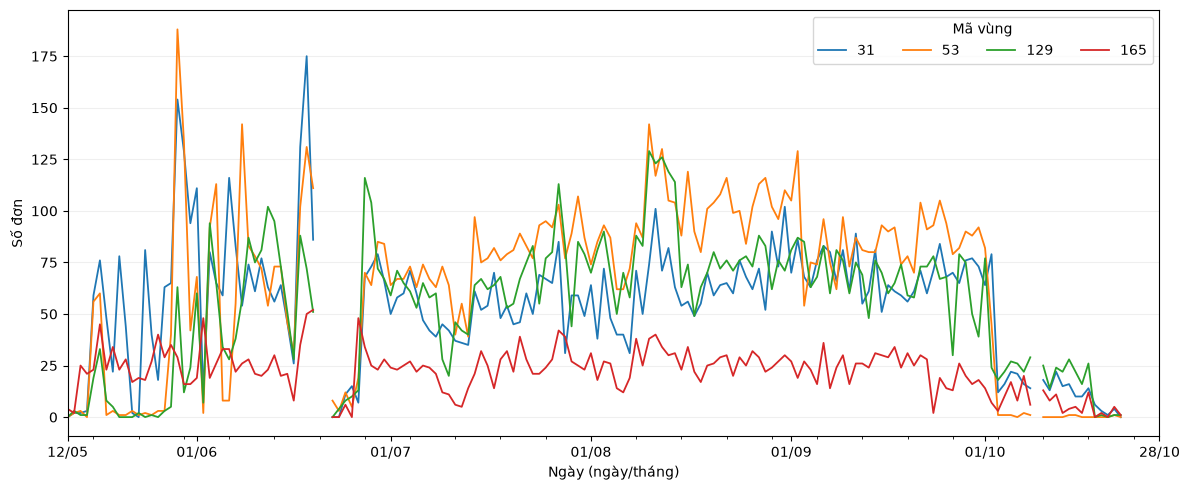

In [2]:
ax = daily.plot(figsize=(12, 5), linewidth=1.3, ylabel="Số đơn", xlabel="Ngày (ngày/tháng)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.legend(title="Mã vùng", ncol=4)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## Tương quan giữa các vùng

So sánh Pearson trên mức số đơn cùng ngày và trên sai phân của hai ngày lịch liền nhau có dữ liệu. Bảng ghi số ngày ghép cặp cho từng hệ số.

,transform,region_a,region_b,paired_days,pearson_r
0,level,31,53,163,0.741
1,level,31,129,163,0.592
2,level,31,165,163,0.532
3,level,53,129,163,0.809
4,level,53,165,163,0.508
5,level,129,165,163,0.489
6,daily_change,31,53,158,0.503
7,daily_change,31,129,158,0.422
8,daily_change,31,165,158,0.008
9,daily_change,53,129,158,0.513


,transform,region_a,region_b,paired_days,pearson_r
0,level,31,53,98,0.489
1,level,31,129,98,0.382
2,level,31,165,98,0.252
3,level,53,129,98,0.562
4,level,53,165,98,0.480
5,level,129,165,98,0.597
6,daily_change,31,53,97,0.366
7,daily_change,31,129,97,0.109
8,daily_change,31,165,97,0.233
9,daily_change,53,129,97,0.334


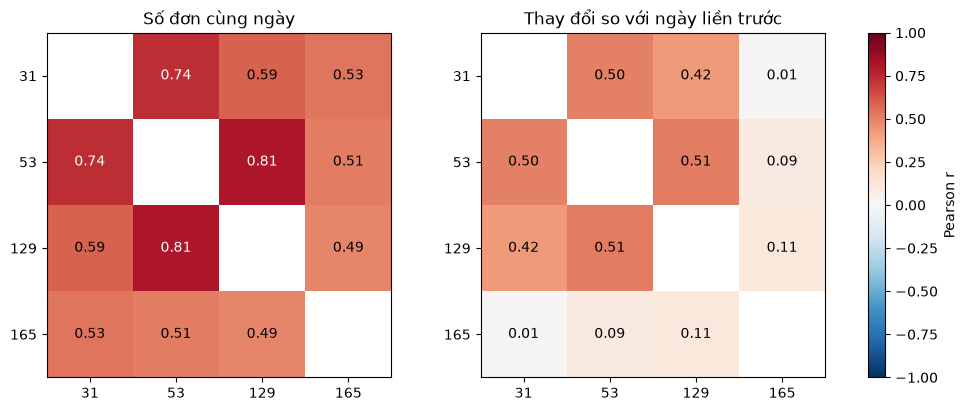

In [3]:
full = compareRegions(panel)
stable = compareRegions(panel.loc[panel[DATE].between(*STABLE_PERIOD)])
display(full.round(3))
display(stable.round(3))

labels = {"level": "Số đơn cùng ngày", "daily_change": "Thay đổi so với ngày liền trước"}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, (transform, title) in zip(axes, labels.items()):
    pairs = full.loc[full["transform"].eq(transform), ["region_a", "region_b", "pearson_r"]]
    reverse = pairs.rename(columns={"region_a": "region_b", "region_b": "region_a"})
    matrix = pd.concat([pairs, reverse]).pivot(index="region_a", columns="region_b", values="pearson_r")
    heatmap = ax.imshow(matrix, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(matrix.columns)), labels=matrix.columns)
    ax.set_yticks(range(len(matrix.index)), labels=matrix.index)
    ax.set_title(title)
    for row, values in enumerate(matrix.to_numpy()):
        for col, value in enumerate(values):
            if pd.notna(value):
                ax.text(col, row, f"{value:.2f}", ha="center", va="center",
                        color="white" if abs(value) > 0.65 else "black")
fig.colorbar(heatmap, ax=axes, label="Pearson r")
plt.show()

## Diễn giải

Toàn kỳ có 163 ngày ghép cặp theo mức số đơn và 158 ngày ghép cặp theo sai phân. Vùng 53 và 129 có tương quan khoảng 0,81 theo mức và 0,51 theo sai phân. Vùng 31 và 165 có tương quan khoảng 0,53 theo mức và gần 0 theo sai phân.

Thứ hạng thay đổi khi chỉ xét 27/06–02/10. Chẳng hạn, tương quan theo mức của vùng 129 và 165 tăng từ khoảng 0,49 lên 0,60. Vì vậy, báo cáo diễn giải từng hệ số theo cách đo và giai đoạn quan sát tương ứng.